In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = sns.load_dataset("titanic")
df.head()


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 100.4 KB


In [4]:
df.shape

(891, 15)

In [5]:
df.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='str')

In [6]:
df.describe(include="all")

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891.000000,891.000000,891,714.000000,891.000000,891.000000,891.000000,889,891,891,891,203,889,891,891
unique,NaN,NaN,2,NaN,NaN,NaN,NaN,3,3,3,2,7,3,2,2
top,NaN,NaN,male,NaN,NaN,NaN,NaN,S,Third,man,True,C,Southampton,no,True
freq,NaN,NaN,577,NaN,NaN,NaN,NaN,644,491,537,537,59,644,549,537
mean,0.383838,2.308642,NaN,29.699118,0.523008,0.381594,32.204208,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,0.486592,0.836071,NaN,14.526497,1.102743,0.806057,49.693429,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,1.000000,NaN,0.420000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,0.000000,2.000000,NaN,20.125000,0.000000,0.000000,7.910400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,0.000000,3.000000,NaN,28.000000,0.000000,0.000000,14.454200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1.000000,3.000000,NaN,38.000000,1.000000,0.000000,31.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
df.dtypes

survived          int64
pclass            int64
sex                 str
age             float64
sibsp             int64
parch             int64
fare            float64
embarked            str
class          category
who                 str
adult_male         bool
deck           category
embark_town         str
alive               str
alone              bool
dtype: object

In [8]:
df.isna().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [9]:
df.nunique()

survived         2
pclass           3
sex              2
age             88
sibsp            7
parch            7
fare           248
embarked         3
class            3
who              3
adult_male       2
deck             7
embark_town      3
alive            2
alone            2
dtype: int64

# Univariate Analysis



## Survived

In [10]:
df['survived'].dtypes

dtype('int64')

In [11]:
df['survived'].describe()

count    891.000000
mean       0.383838
std        0.486592
min        0.000000
25%        0.000000
50%        0.000000
75%        1.000000
max        1.000000
Name: survived, dtype: float64

In [12]:
df['survived'].unique()

array([0, 1])

In [13]:
df['survived'].isna().sum()

np.int64(0)

In [14]:
df['survived'].value_counts()

survived
0    549
1    342
Name: count, dtype: int64

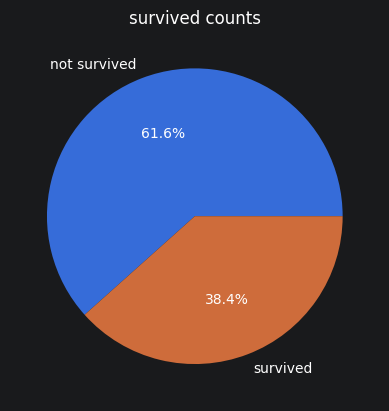

In [15]:
survived_counts = df['survived'].value_counts()
plt.pie(survived_counts,labels=['not survived','survived'] ,autopct='%1.1f%%')
plt.title('survived counts')
plt.show()

<div dir="rtl" style="text-align: right; line-height: 2;">

### بررسی ستون Survived

در این بخش، وضعیت بقا و مرگ مسافران کشتی تایتانیک مورد بررسی قرار گرفت. ستون `Survived` به‌عنوان متغیر هدف (Target Variable) در دیتاست شناخته می‌شود و شامل دو مقدار است:

- مقدار 0: نشان‌دهنده مسافرانی که جان خود را از دست داده‌اند.
- مقدار 1: نشان‌دهنده مسافرانی که از حادثه جان سالم به در برده‌اند.

ابتدا با استفاده از تابع `unique()` مقادیر یکتای این ستون شناسایی شد. سپس با استفاده از تابع `value_counts()` تعداد مسافران در هر گروه محاسبه گردید.

در ادامه، با استفاده از نمودار دایره‌ای (Pie Chart)، توزیع و درصد مسافران زنده‌مانده و فوت‌شده به‌صورت بصری نمایش داده شد.

**هدف از بررسی:**

هدف از این بررسی، شناخت توزیع متغیر هدف، تعیین نسبت مسافران نجات‌یافته به مسافران فوت‌شده و شناسایی میزان عدم تعادل بین دو گروه است. این شناخت به ما کمک می‌کند تا در مراحل بعدی تحلیل، ارتباط ویژگی‌هایی مانند جنسیت، سن و کلاس بلیت را با احتمال زنده ماندن مسافران بررسی کنیم.

</div>

## Sex

In [16]:
df['sex'].dtypes

<StringDtype(na_value=nan)>

In [17]:
df['sex'].unique()

<ArrowStringArray>
['male', 'female']
Length: 2, dtype: str

In [18]:
df['sex'].isna().sum()

np.int64(0)

In [19]:
df['sex'].value_counts()

sex
male      577
female    314
Name: count, dtype: int64

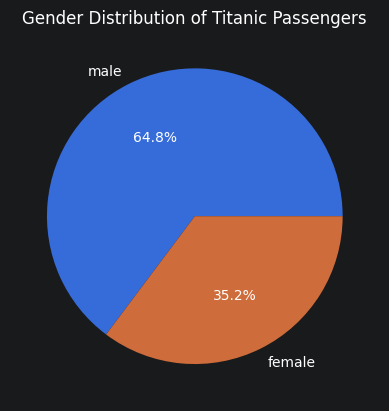

In [20]:
sex_counts = df['sex'].value_counts()
plt.pie(sex_counts,labels=['male','female'],autopct='%1.1f%%')
plt.title('Gender Distribution of Titanic Passengers')
plt.show()

<div dir="rtl" style="text-align: right; line-height: 2;">

### بررسی ستون Sex

در این بخش، توزیع جنسیت مسافران کشتی تایتانیک مورد بررسی قرار گرفت. ستون `Sex` شامل دو مقدار `male` و `female` است که به‌ترتیب نشان‌دهنده مسافران مرد و زن هستند.

ابتدا با استفاده از تابع `unique()` مقادیر یکتای این ستون شناسایی شد. سپس با استفاده از تابع `value_counts()` تعداد مسافران در هر گروه جنسیتی محاسبه گردید.

در ادامه، با استفاده از نمودار دایره‌ای (Pie Chart)، توزیع و درصد مسافران مرد و زن به‌صورت بصری نمایش داده شد.

**هدف از بررسی:**

هدف از این بررسی، شناخت ترکیب جنسیتی مسافران و تعیین نسبت مردان به زنان در کل جمعیت مسافران است. این اطلاعات در مراحل بعدی تحلیل، برای بررسی ارتباط جنسیت با وضعیت بقای مسافران (Survived) و مقایسه میزان نجات‌یافتگان در میان دو گروه مورد استفاده قرار خواهد گرفت.

</div>

## Age

In [21]:
df['age'].describe()

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: age, dtype: float64

In [22]:
df['age'].isna().sum()

np.int64(177)

In [23]:
len(df['age'].unique())

89

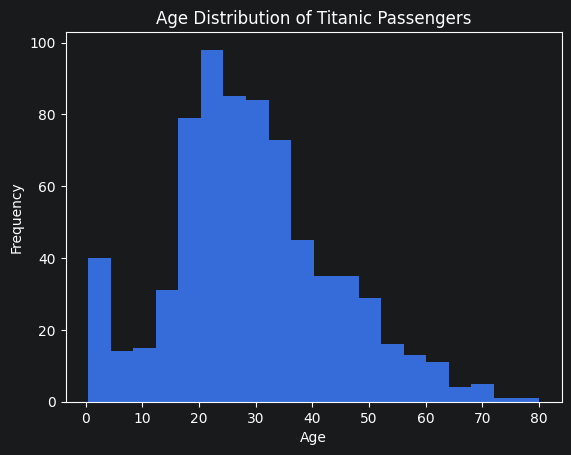

In [24]:
plt.hist(df['age'] , bins=20)

plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Age Distribution of Titanic Passengers')

plt.show()

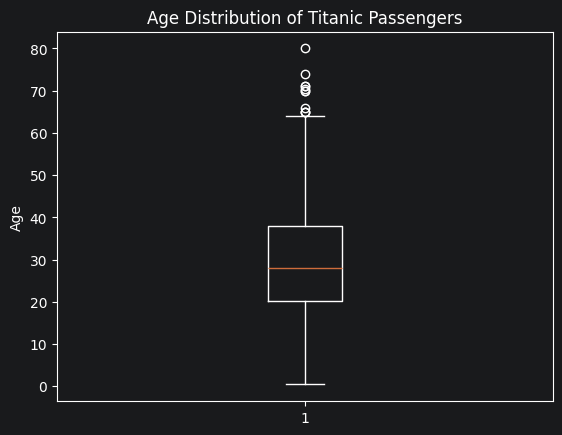

In [25]:
plt.boxplot(df['age'].dropna())

plt.ylabel('Age')
plt.title('Age Distribution of Titanic Passengers')

plt.show()

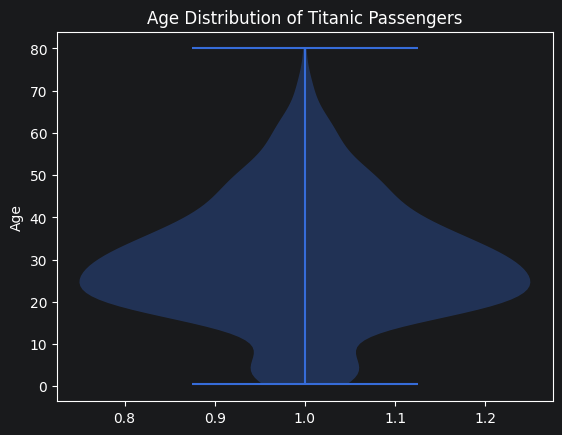

In [26]:
plt.violinplot(df['age'].dropna())

plt.ylabel('Age')
plt.title('Age Distribution of Titanic Passengers')

plt.show()

<div dir="rtl" style="text-align: right; line-height: 2;">

### بررسی ستون Age

در این بخش، ویژگی سنی مسافران کشتی تایتانیک مورد بررسی قرار گرفت. ستون `Age` یکی از متغیرهای عددی مهم در دیتاست محسوب می‌شود که می‌تواند در تحلیل الگوی بقا و بررسی تفاوت‌های رفتاری و جمعیتی مسافران نقش داشته باشد.

در مرحله نخست، با استفاده از شاخص‌های آماری توصیفی، اطلاعاتی نظیر میانگین، میانه، انحراف معیار، حداقل و حداکثر سن استخراج شد. همچنین تعداد مقادیر یکتا و داده‌های گمشده این ستون مورد بررسی قرار گرفت.

برای شناخت بهتر ساختار توزیع سنی، از سه نمودار آماری استفاده شد:

- **Histogram:** برای بررسی فراوانی سنین و شناسایی محدوده‌های سنی با بیشترین تمرکز مسافران.
- **Boxplot:** برای بررسی میانه، چارک‌ها، میزان پراکندگی و شناسایی مقادیر پرت احتمالی.
- **Violin Plot:** برای نمایش شکل توزیع و بررسی تراکم داده‌ها در محدوده‌های سنی مختلف.

**نتایج و مشاهدات:**

بر اساس نمودار Histogram، بیشترین تمرکز سنی مسافران در محدوده ۲۰ تا ۳۰ سال مشاهده شد. همچنین بررسی نمودار Boxplot نشان داد که بخش میانی توزیع سنی، یعنی ۵۰ درصد داده‌های معتبر، تقریباً در بازه ۲۰ تا ۴۰ سال قرار دارد.

نمودار Violin نیز با نمایش تراکم داده‌ها، امکان بررسی دقیق‌تر تمرکز سنین مختلف را فراهم می‌کند. علاوه بر این، تعدادی از سنین خارج از محدوده معمول نمودار Boxplot قرار گرفته‌اند که به‌عنوان مقادیر پرت احتمالی شناسایی می‌شوند؛ با این حال، این مقادیر لزوماً نشان‌دهنده خطای ثبت داده نیستند.

**هدف از بررسی:**

هدف از تحلیل این ستون، شناخت ساختار سنی مسافران، بررسی نحوه پراکندگی سنین، شناسایی تمرکز جمعیت در بازه‌های سنی مختلف و ارزیابی کیفیت داده‌ها از نظر مقادیر گمشده و پرت احتمالی است. همچنین نتایج این بررسی می‌تواند در مراحل بعدی تحلیل، برای ارزیابی ارتباط سن با متغیر هدف `Survived` و بررسی تفاوت نرخ بقا در گروه‌های سنی مختلف مورد استفاده قرار گیرد.

</div>

## pclass

In [27]:
df['pclass'].dtypes

dtype('int64')

In [28]:
df['pclass'].describe()

count    891.000000
mean       2.308642
std        0.836071
min        1.000000
25%        2.000000
50%        3.000000
75%        3.000000
max        3.000000
Name: pclass, dtype: float64

In [29]:
df['pclass'].unique()

array([3, 1, 2])

In [30]:
df['pclass'].value_counts()

pclass
3    491
1    216
2    184
Name: count, dtype: int64

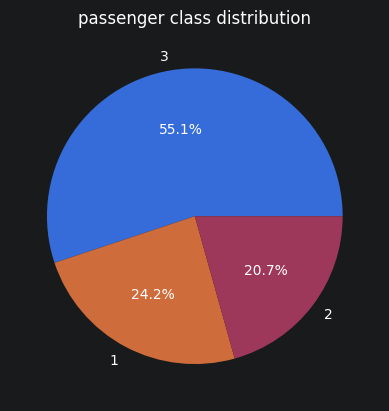

In [31]:
pclass_count = df['pclass'].value_counts()

plt.pie(pclass_count,labels=pclass_count.index,autopct='%1.1f%%')

plt.title('passenger class distribution')
plt.show()


<div dir="rtl" style="text-align: right; line-height: 2;">

### بررسی ستون Pclass

در این بخش، کلاس بلیت مسافران کشتی تایتانیک مورد بررسی قرار گرفت. ستون `Pclass` نشان‌دهنده کلاس اقتصادی بلیت مسافران است و شامل سه مقدار می‌شود:

- مقدار 1: کلاس اول (First Class)
- مقدار 2: کلاس دوم (Second Class)
- مقدار 3: کلاس سوم (Third Class)

ابتدا با استفاده از تابع `unique()` مقادیر یکتای این ستون شناسایی شد. سپس با استفاده از تابع `value_counts()` تعداد مسافران در هر کلاس محاسبه گردید.

در ادامه، با استفاده از نمودار دایره‌ای (Pie Chart)، توزیع و درصد مسافران در هر یک از سه کلاس بلیت به‌صورت بصری نمایش داده شد.

**هدف از بررسی:**

هدف از این بررسی، شناخت توزیع مسافران بر اساس کلاس بلیت و مشخص کردن سهم هر کلاس از کل مسافران است. این اطلاعات در مراحل بعدی تحلیل به ما کمک می‌کند تا ارتباط بین کلاس بلیت و احتمال زنده ماندن مسافران در حادثه تایتانیک را بررسی کنیم.

</div>

## sibsp

In [32]:
df['sibsp'].dtypes

dtype('int64')

In [33]:
df['sibsp'].describe()

count    891.000000
mean       0.523008
std        1.102743
min        0.000000
25%        0.000000
50%        0.000000
75%        1.000000
max        8.000000
Name: sibsp, dtype: float64

In [34]:
df['sibsp'].unique()

array([1, 0, 3, 4, 2, 5, 8])

In [35]:
df['sibsp'].value_counts()

sibsp
0    608
1    209
2     28
4     18
3     16
8      7
5      5
Name: count, dtype: int64

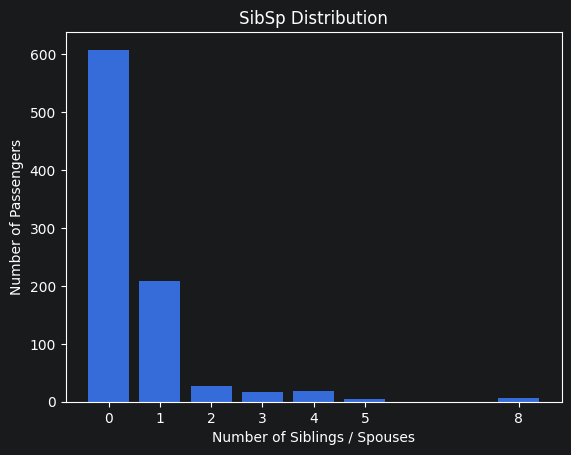

In [36]:
sibsp_count = df['sibsp'].value_counts().sort_index()

plt.bar(
    sibsp_count.index,
    sibsp_count.values
)

plt.title('SibSp Distribution')
plt.xlabel('Number of Siblings / Spouses')
plt.ylabel('Number of Passengers')
plt.xticks(sibsp_count.index)
plt.show()

<div dir="rtl" style="text-align: right; line-height: 2;">

### بررسی ستون SibSp

در این بخش، تعداد خواهر و برادرها و همسرانی که همراه هر مسافر در کشتی تایتانیک حضور داشتند، مورد بررسی قرار گرفت. ستون `SibSp` تعداد این افراد را برای هر مسافر نشان می‌دهد.

ابتدا با استفاده از تابع `unique()` مقادیر یکتای این ستون شناسایی شد. سپس با استفاده از تابع `value_counts()` تعداد مسافران در هر گروه محاسبه گردید.

در ادامه، با استفاده از نمودار هیستوگرام (Histogram)، توزیع تعداد اعضای خانواده همراه مسافران به‌صورت بصری نمایش داده شد.

**نتیجه بررسی:**

بر اساس نمودار، بیشترین تعداد مسافران دارای مقدار صفر در این ستون بودند؛ به این معنی که بیشتر مسافران بدون حضور خواهر، برادر یا همسر خود سفر کرده بودند.

**هدف از بررسی:**

هدف از این بررسی، شناخت وضعیت همراهان خانوادگی مسافران و بررسی نحوه توزیع آن‌ها است. این اطلاعات در مراحل بعدی تحلیل می‌تواند به ما کمک کند تا ارتباط بین تعداد اعضای خانواده و احتمال زنده ماندن مسافران را بررسی کنیم.

</div>

## parch

In [37]:
df['parch'].dtype

dtype('int64')

In [38]:
df['parch'].describe()

count    891.000000
mean       0.381594
std        0.806057
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max        6.000000
Name: parch, dtype: float64

In [39]:
df['parch'].unique()

array([0, 1, 2, 5, 3, 4, 6])

In [40]:
df['parch'].value_counts()

parch
0    678
1    118
2     80
5      5
3      5
4      4
6      1
Name: count, dtype: int64

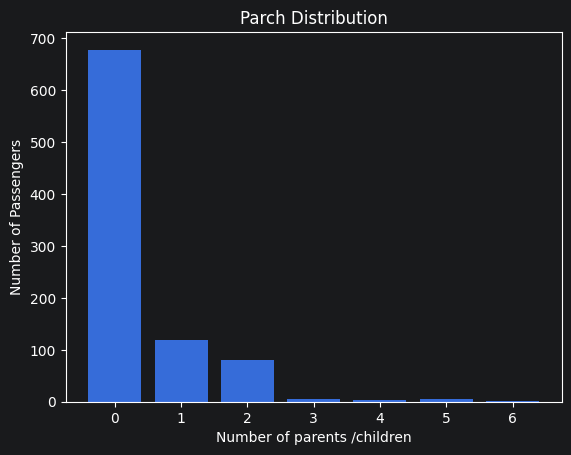

In [41]:
parch_count = df['parch'].value_counts()

plt.bar(parch_count.index,parch_count.values)
plt.title('Parch Distribution')
plt.xlabel('Number of parents /children')
plt.ylabel('Number of Passengers')
plt.show()

## Fare

In [42]:
df['fare'].dtype

dtype('float64')

In [43]:
df['fare'].describe()

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: fare, dtype: float64

In [44]:
len(df['fare'].unique())

248

In [45]:
df['fare'].value_counts().head()

fare
8.0500     43
13.0000    42
7.8958     38
7.7500     34
26.0000    31
Name: count, dtype: int64

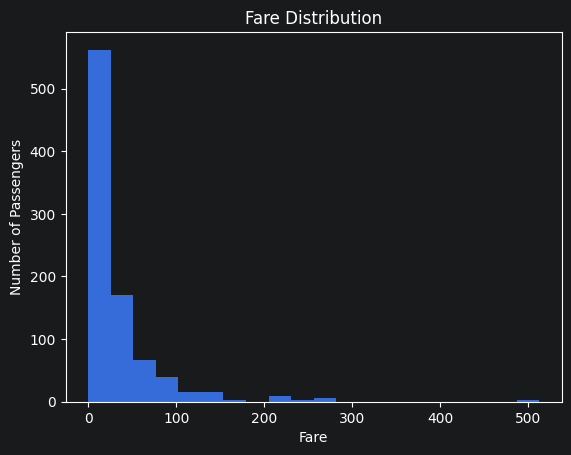

In [46]:
plt.hist(df['fare'],bins=20)

plt.title('Fare Distribution')
plt.xlabel('Fare')
plt.ylabel('Number of Passengers')

plt.show()

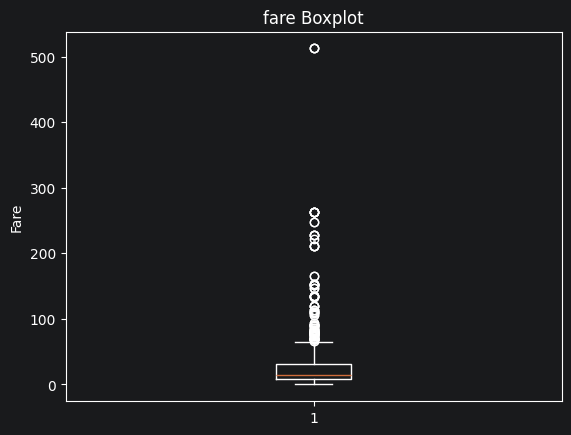

In [47]:
plt.boxplot(df['fare'].dropna())

plt.title('fare Boxplot')
plt.ylabel('Fare')

plt.show()

<div dir="rtl" style="text-align: right; line-height: 2;">

### بررسی ستون Fare

ستون `Fare` نشان‌دهنده مبلغ کرایه پرداخت‌شده توسط هر مسافر است. این ستون از نوع متغیرهای عددی پیوسته (Continuous Numerical) محسوب می‌شود.

در این بخش، برای بررسی توزیع و پراکندگی مقادیر از نمودارهای زیر استفاده شد:

- **Histogram:** برای بررسی توزیع فراوانی کرایه‌های پرداخت‌شده توسط مسافران.
- **Boxplot:** برای بررسی پراکندگی داده‌ها، میانه، چارک‌ها و شناسایی مقادیر پرت احتمالی.

**نتایج و مشاهدات:**

با بررسی نمودار Histogram مشخص شد که توزیع کرایه‌ها نامتقارن بوده و بیشتر مقادیر در محدوده کرایه‌های پایین‌تر قرار دارند.

همچنین در نمودار Boxplot تعدادی مقدار پرت احتمالی در محدوده کرایه‌های بالا مشاهده شد.

با توجه به ماهیت داده‌ها، این مقادیر لزوماً نشان‌دهنده خطای ثبت اطلاعات نیستند و می‌توانند ناشی از تفاوت قیمت بلیت‌ها باشند.

**هدف از بررسی:**

شناخت الگوی توزیع کرایه‌ها، بررسی میزان پراکندگی و آماده‌سازی داده‌ها برای تحلیل‌های بعدی، به‌ویژه بررسی ارتباط مبلغ کرایه با کلاس مسافران و احتمال زنده‌ماندن آن‌ها.

</div>

### embarked

In [48]:
df['embarked'].dtype

<StringDtype(na_value=nan)>

In [49]:
df['embarked'].info()

<class 'pandas.Series'>
RangeIndex: 891 entries, 0 to 890
Series name: embarked
Non-Null Count  Dtype
--------------  -----
889 non-null    str  
dtypes: str(1)
memory usage: 8.1 KB


In [50]:
print(df['embarked'].isna().sum())

2


In [51]:
print(df['embarked'].unique())

<ArrowStringArray>
['S', 'C', 'Q', nan]
Length: 4, dtype: str


In [52]:
df['embarked'].value_counts()

embarked
S    644
C    168
Q     77
Name: count, dtype: int64

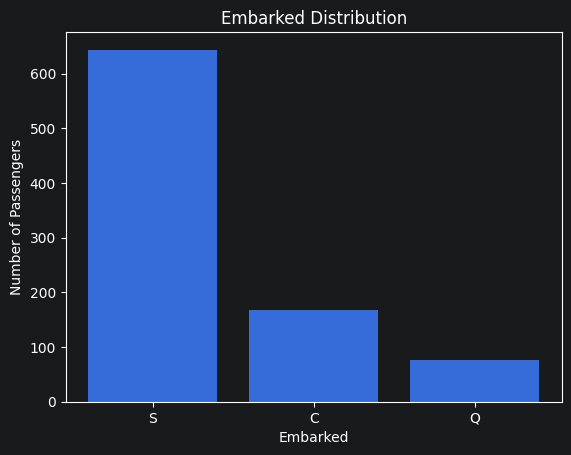

In [53]:
embarked_count = df['embarked'].value_counts()

plt.bar(embarked_count.index,embarked_count.values)

plt.title('Embarked Distribution')
plt.xlabel('Embarked')
plt.ylabel('Number of Passengers')

plt.show()

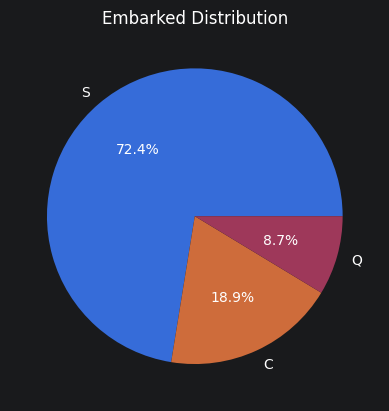

In [54]:
embarked_count = df['embarked'].value_counts()

plt.pie(
    embarked_count,
    labels=embarked_count.index,
    autopct='%1.1f%%'
)

plt.title('Embarked Distribution')
plt.show()

<div dir="rtl" style="text-align: right; line-height: 2;">

### بررسی ستون Embarked

ستون `Embarked` نشان‌دهنده بندری است که مسافران از آنجا سوار کشتی تایتانیک شده‌اند. این ستون شامل سه مقدار دسته‌ای است:

- مقدار S: بندر Southampton
- مقدار C: بندر Cherbourg
- مقدار Q: بندر Queenstown

در این بخش، برای بررسی توزیع فراوانی مقادیر از نمودارهای Bar Chart و Pie Chart استفاده شد.

**نتایج و مشاهدات:**

با بررسی نمودارها مشخص شد که بندر Southampton بیشترین تعداد مسافر را به خود اختصاص داده است. پس از آن بندر Cherbourg و در نهایت بندر Queenstown قرار دارند.

همچنین این ستون دارای ۲ مقدار گمشده (Missing Values) است.

</div>

# تحلیل روابط بین متغیرها (Multivariate Analysis)
<div dir="rtl" style="text-align: right; line-height: 2;">



در این بخش، پس از بررسی تک‌متغیره ستون‌های دیتاست، وارد مرحله تحلیل روابط بین متغیرها می‌شویم.

هدف این مرحله بررسی ارتباط ویژگی‌های مختلف مسافران با وضعیت بقای آن‌ها و شناسایی الگوهای موجود در داده‌ها است.

</div>

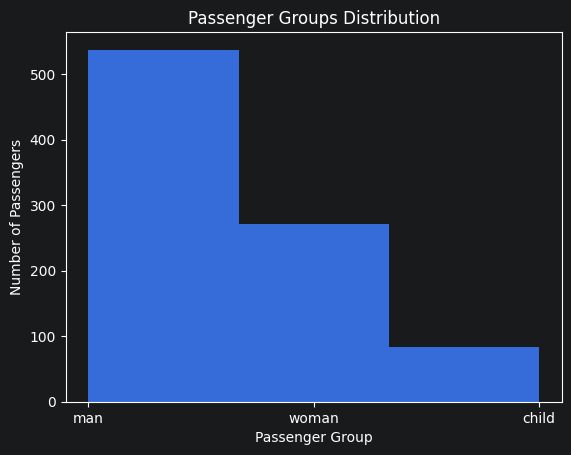

In [55]:
plt.hist(df["who"], bins=3)

plt.title('Passenger Groups Distribution')
plt.xlabel('Passenger Group')
plt.ylabel('Number of Passengers')

plt.show()

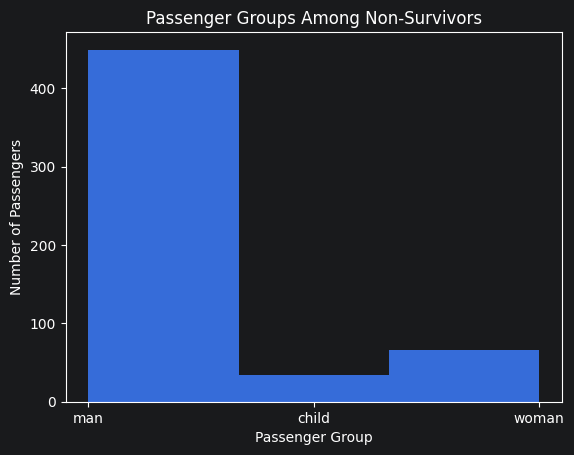

In [56]:
plt.hist(df[df["survived"]==0]["who"], bins=3)

plt.title('Passenger Groups Among Non-Survivors')
plt.xlabel('Passenger Group')
plt.ylabel('Number of Passengers')

plt.show()

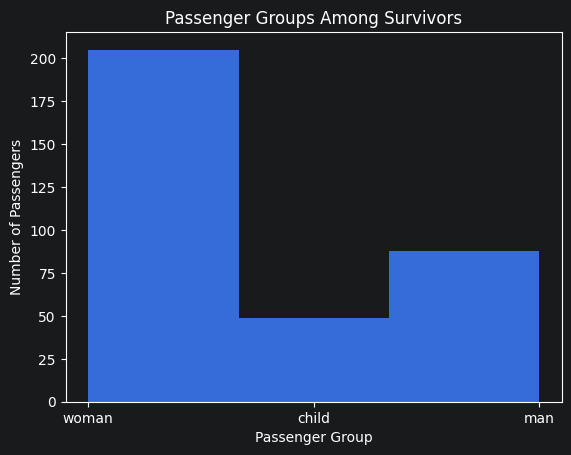

In [57]:
plt.hist(df[df["survived"]==1]["who"], bins=3)

plt.title('Passenger Groups Among Survivors')
plt.xlabel('Passenger Group')
plt.ylabel('Number of Passengers')

plt.show()

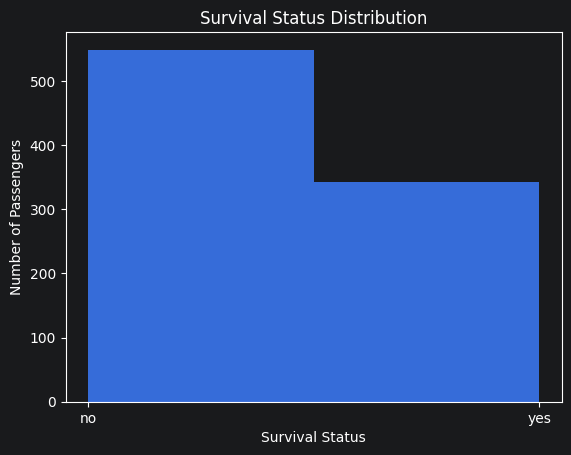

In [59]:
plt.hist(df['alive'], bins=2)

plt.title('Survival Status Distribution')
plt.xlabel('Survival Status')
plt.ylabel('Number of Passengers')

plt.show()

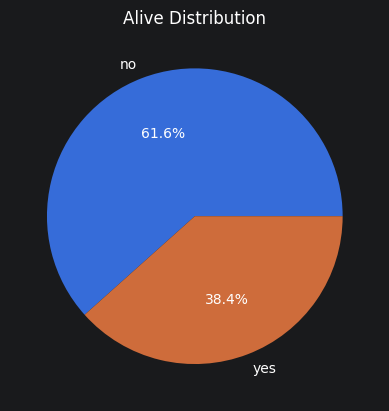

In [61]:
alive_count = df['alive'].value_counts()

plt.pie(
    alive_count,
    labels=alive_count.index,
    autopct='%1.1f%%'
)

plt.title('Alive Distribution')
plt.show()

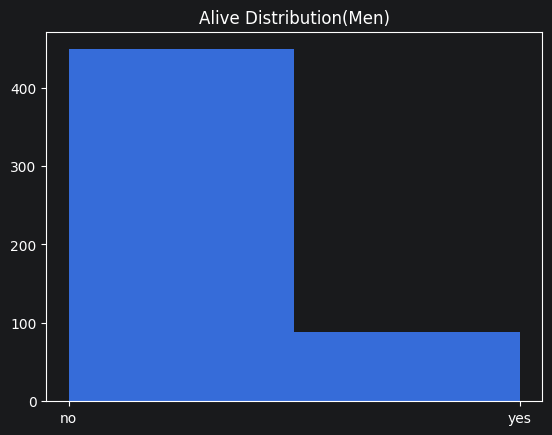

In [64]:
plt.hist(df[df['who']=='man']['alive'], bins=2)
plt.title('Alive Distribution(Men)')
plt.show()

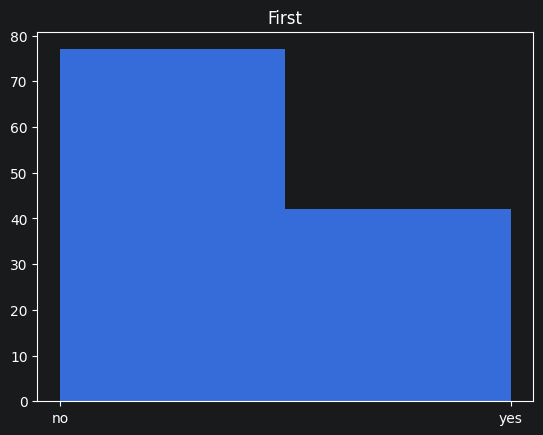

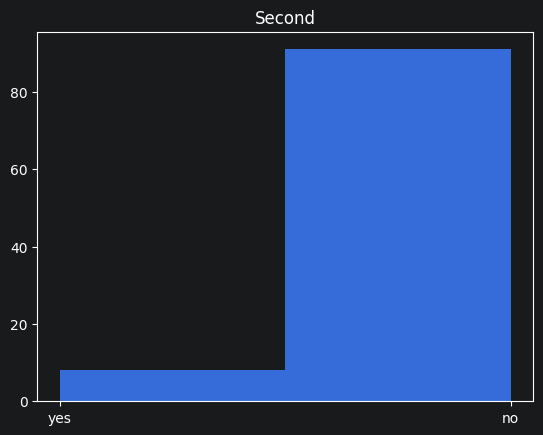

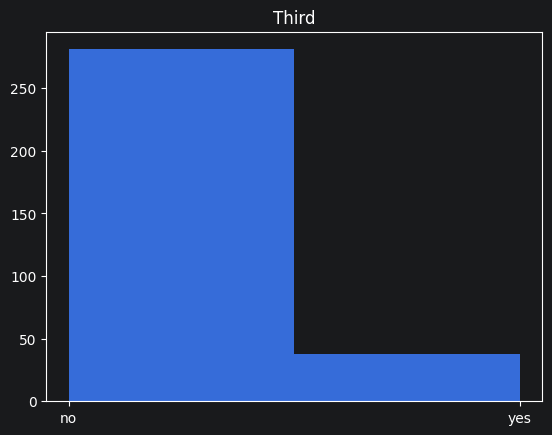

In [66]:
for titanic_class in np.unique(df["class"]):
    alive_count = df[
        (df["who"] == "man") &
        (df["class"] == titanic_class)
    ]["alive"].value_counts()

    plt.bar(alive_count.index, alive_count.values)

    plt.title(titanic_class)
    plt.xlabel("Survival Status")
    plt.ylabel("Number of Passengers")
    plt.show()

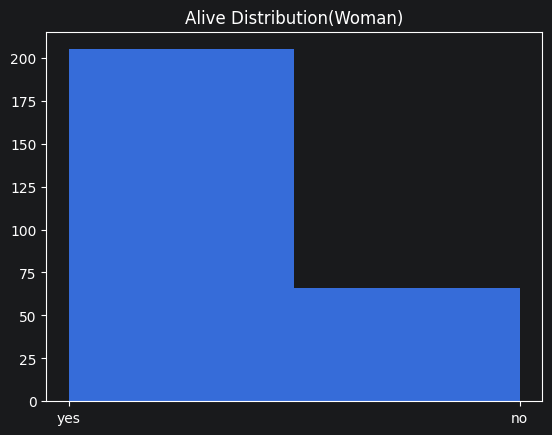

In [67]:
plt.hist(df[df["who"]=="woman"]["alive"],bins=2)
plt.title('Alive Distribution(Woman)')
plt.show()

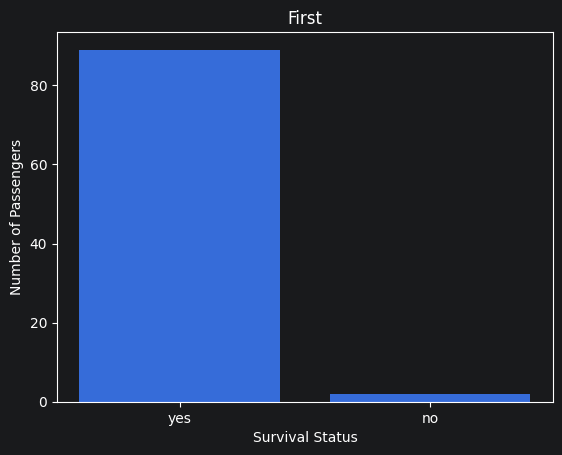

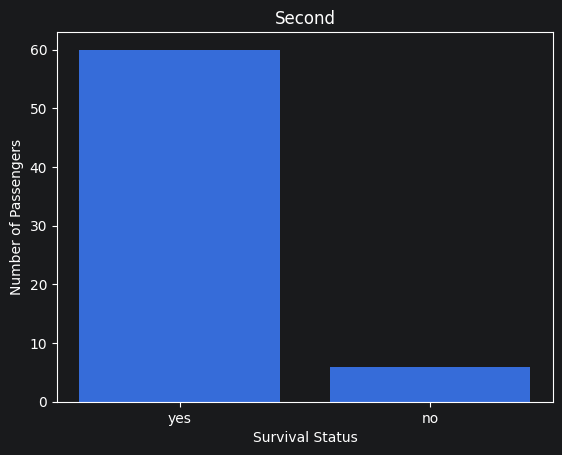

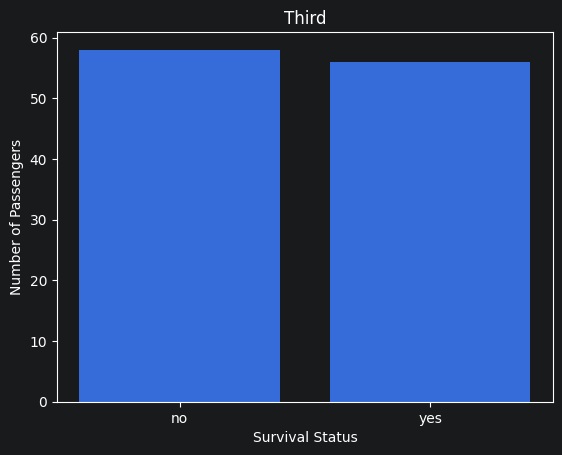

In [71]:
for titanic_class in np.unique(df["class"]):
    alive_count = df[
        (df["who"] == "woman") &
        (df["class"] == titanic_class)
    ]["alive"].value_counts()

    plt.bar(alive_count.index, alive_count.values)

    plt.title(titanic_class)
    plt.xlabel("Survival Status")
    plt.ylabel("Number of Passengers")
    plt.show()

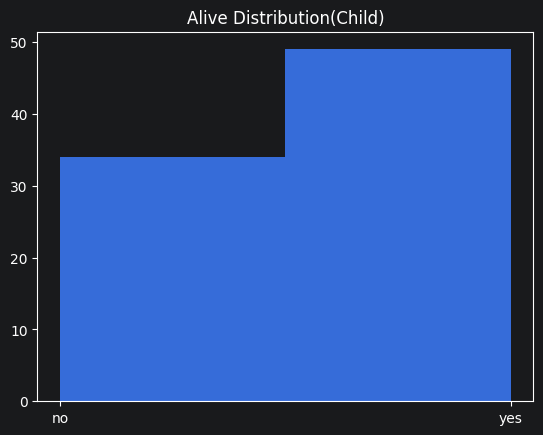

In [69]:
plt.hist(df[df["who"]=="child"]["alive"], bins=2)
plt.title('Alive Distribution(Child)')
plt.show()

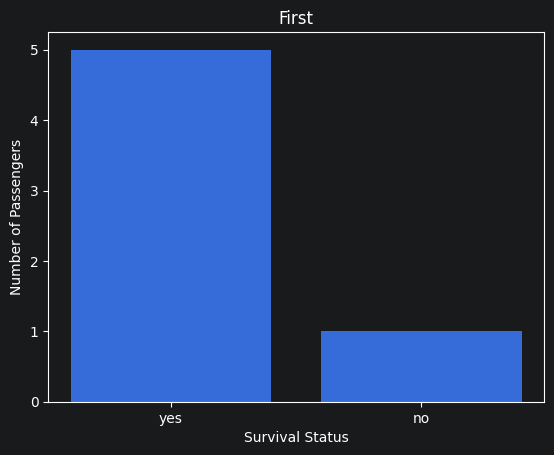

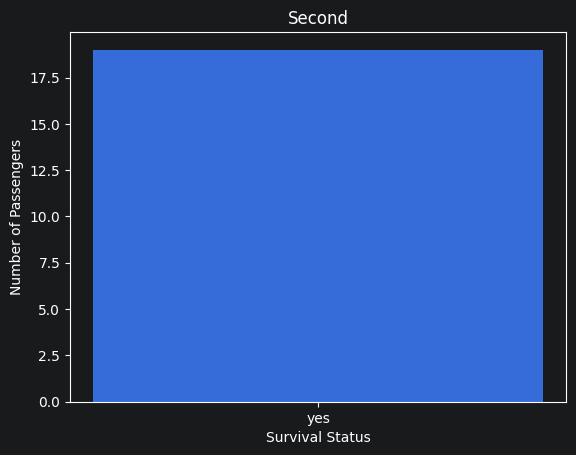

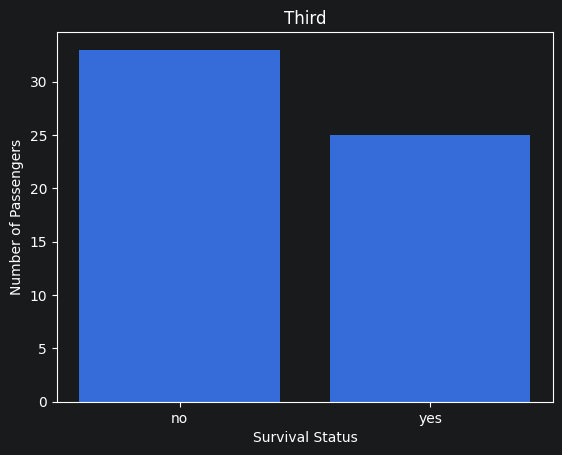

In [72]:
for titanic_class in np.unique(df["class"]):
    alive_count = df[
        (df["who"] == "child") &
        (df["class"] == titanic_class)
    ]["alive"].value_counts()

    plt.bar(alive_count.index, alive_count.values)

    plt.title(titanic_class)
    plt.xlabel("Survival Status")
    plt.ylabel("Number of Passengers")
    plt.show()

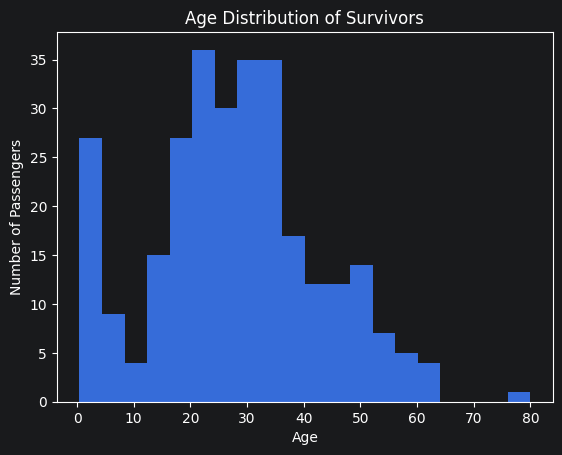

In [73]:
plt.hist(df[df['survived'] == 1]['age'].dropna(),bins=20)

plt.title('Age Distribution of Survivors')
plt.xlabel('Age')
plt.ylabel('Number of Passengers')

plt.show()

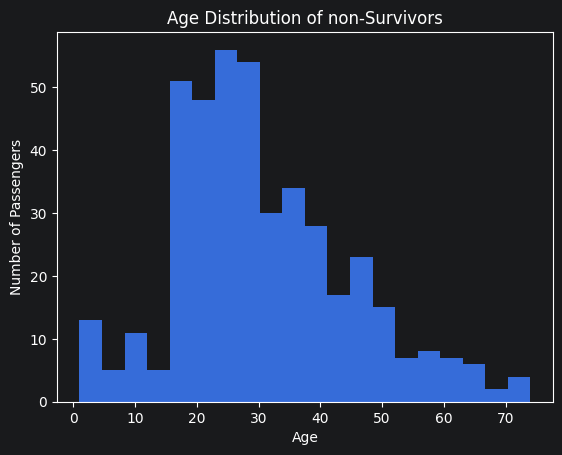

In [75]:
plt.hist(df[df['survived'] == 0]['age'].dropna(),bins=20)

plt.title('Age Distribution of non-Survivors')
plt.xlabel('Age')
plt.ylabel('Number of Passengers')

plt.show()

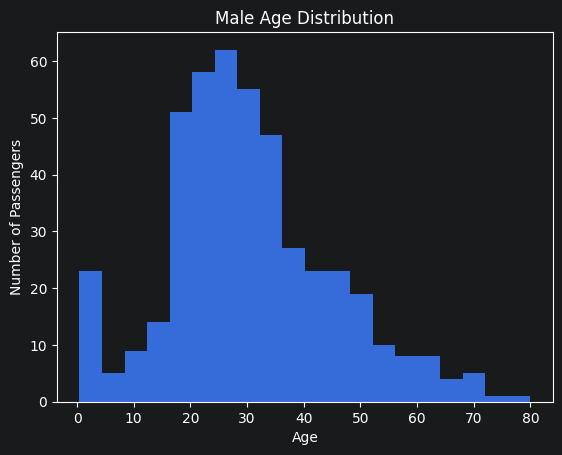

In [78]:
plt.hist(df[df['sex'] == 'male']['age'].dropna(), bins=20)

plt.title('Male Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Passengers')
plt.show()

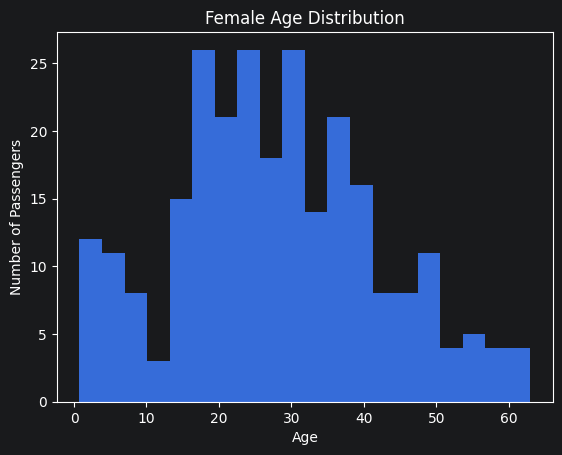

In [79]:
plt.hist(df[df['sex'] == 'female']['age'].dropna(), bins=20)

plt.title('Female Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Passengers')
plt.show()

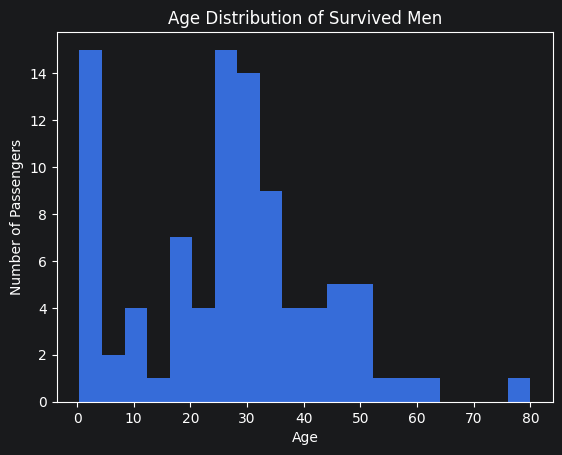

In [80]:
plt.hist(df[(df['sex'] == 'male') & (df['survived'] == 1)]['age'].dropna(),bins=20)

plt.title('Age Distribution of Survived Men')
plt.xlabel('Age')
plt.ylabel('Number of Passengers')

plt.show()

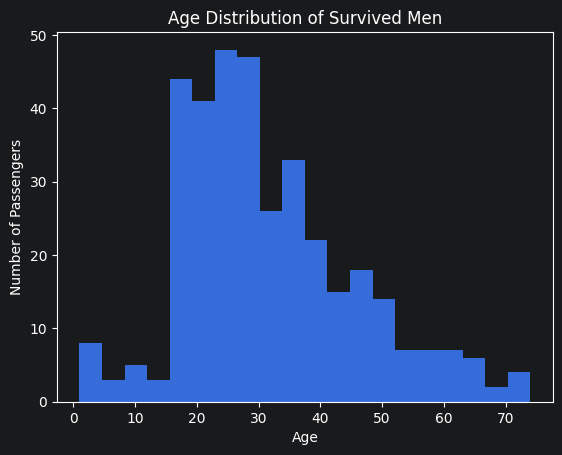

In [81]:
plt.hist(df[(df['sex'] == 'male') & (df['survived'] == 0)]['age'].dropna(),bins=20)

plt.title('Age Distribution of non-Survived Men')
plt.xlabel('Age')
plt.ylabel('Number of Passengers')

plt.show()

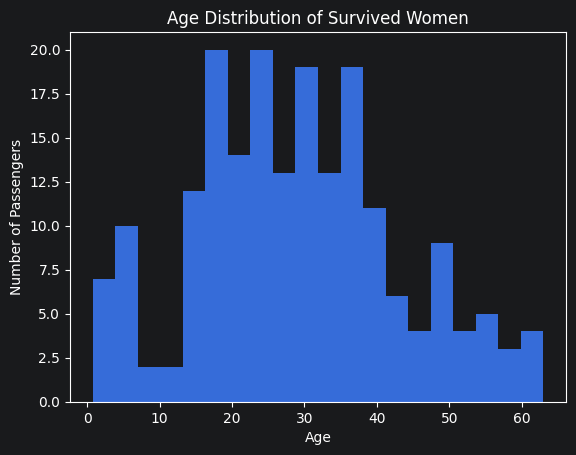

In [82]:
plt.hist(df[(df['sex'] == 'female') & (df['survived'] == 1)]['age'].dropna(),bins=20)

plt.title('Age Distribution of Survived Women')
plt.xlabel('Age')
plt.ylabel('Number of Passengers')

plt.show()

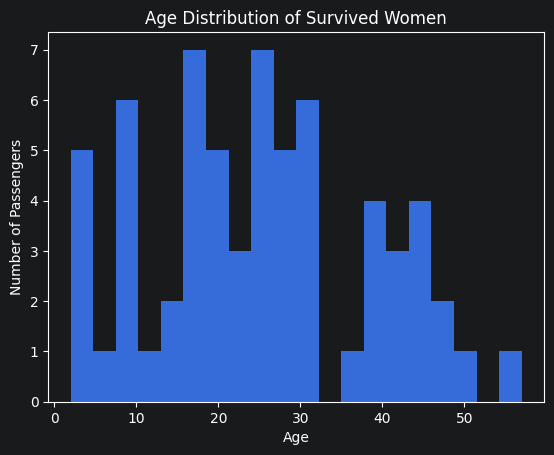

In [83]:
plt.hist(df[(df['sex'] == 'female') & (df['survived'] == 0)]['age'].dropna(),bins=20)

plt.title('Age Distribution of Survived Women')
plt.xlabel('Age')
plt.ylabel('Number of Passengers')

plt.show()

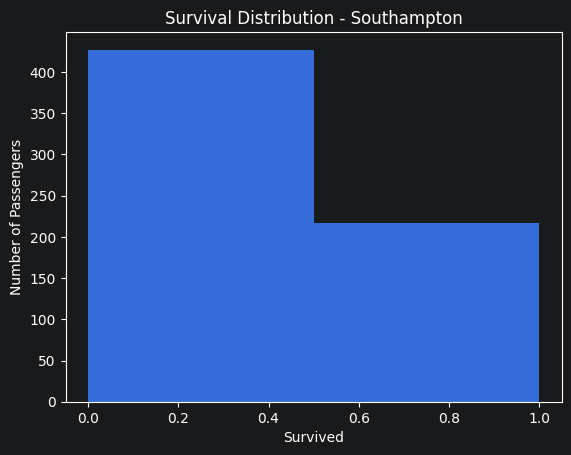

In [87]:
plt.hist(df[df['embarked'] == 'S']['survived'], bins=2)

plt.title('Survival Distribution - Southampton')
plt.xlabel('Survived')
plt.ylabel('Number of Passengers')
plt.show()

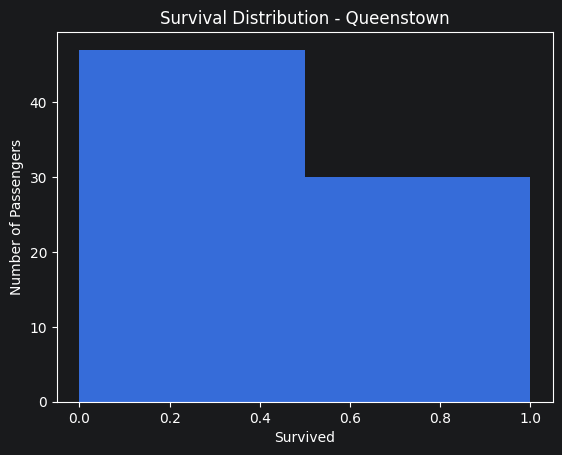

In [88]:
plt.hist(df[df['embarked'] == 'Q']['survived'], bins=2)

plt.title('Survival Distribution - Queenstown')
plt.xlabel('Survived')
plt.ylabel('Number of Passengers')
plt.show()

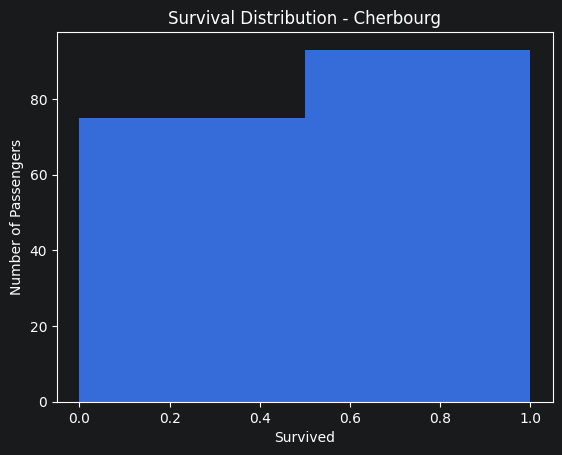

In [89]:
plt.hist(df[df['embarked'] == 'C']['survived'], bins=2)

plt.title('Survival Distribution - Cherbourg')
plt.xlabel('Survived')
plt.ylabel('Number of Passengers')
plt.show()